# Hertha: a complete multimodal asteroid inverse

## 1. Problem

We recover the entire402vertex three-dimensional body-frame surface, spin and
registration/radiometric quantities from real reduced astronomical measurements.
The data are30relative lightcurves/923samples, two150×150AO images with measured
PSFs, and18occultation chords.135is the asteroid identifier, not a curve count.
This notebook actively recomputes the selected conditional estimate. Original
author-code results remain explicitly identified comparisons, never ground truth.

Brightness measures illuminated projected area, images constrain projected
structure after blur, and occultation endpoints constrain size and silhouette.
None supplies independent complete three-dimensional surface truth.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time,hashlib,tempfile,importlib.util
ROOT=next(folder for folder in [Path.cwd(),*Path.cwd().parents] if (folder/'src').is_dir() and (folder/'data/raw_data.npz').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from src.preprocessing import load_observations
from src.physics_model import octantoid,lightcurve_operator,CPP_SOURCE
from src.solvers import initial_parameters
from src.main import run
from src import visualization as viz
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.titlesize':10,'axes.labelsize':9,'figure.titlesize':16,'pdf.fonttype':42,'svg.fonttype':'none'})
REFERENCE=ROOT/'notebooks/reference_outputs'
FIGURES=Path(os.environ.get('IMAGING_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging101-hertha-review-figures')))
environment=dict(python=sys.executable,python_version=sys.version,numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,backend=matplotlib.get_backend(),math_source_sha256=hashlib.sha256(CPP_SOURCE.encode()).hexdigest(),threads={key:os.environ.get(key,'not set') for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']})
assert 'inline' in str(environment['backend']).lower(),environment
print(json.dumps(environment,indent=2))
spec=importlib.util.spec_from_file_location('hertha_independent_review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as archive:raw={key:archive[key] for key in archive.files}
data=load_observations(ROOT/'data/raw_data.npz')
def load_npz(name):
    with np.load(REFERENCE/name,allow_pickle=False) as archive:return {key:archive[key] for key in archive.files}
source=load_npz('original_O1.npz');other=load_npz('original_O0.npz');subdivision=load_npz('original_subdivision_snapshot.npz')
def show(fig,name,numeric):
    viz.save_figure(fig,name,FIGURES,numeric);display(fig);plt.close(fig)


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python_version": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "inline",
  "math_source_sha256": "fecee2ce9f6652099e9f13159ceacb452fa57c768ff1d3393a8c1c0e607261d5",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}


## 2. Data

The two image/PSF pairs use the native author150×150windows. The source's
nonnegative clipping, center phase, DC normalization and removal are retained;
all11399remaining complex frequency samples per exposure are used. The original
image name `jittered` refers to astronomical image reduction, not newly generated
random observations. The four complete original FFTarrays agree with local
preparation to below7×10⁻¹⁶. AO/occultation dates include the source light-time corrections; photometric
dates are the supplied JD minus the epoch only, with no additional correction
in the selected reader. All known directions
are supplied, together with the fixed target-independent representation grid.
No postfit endpoint or photometric mask is introduced.

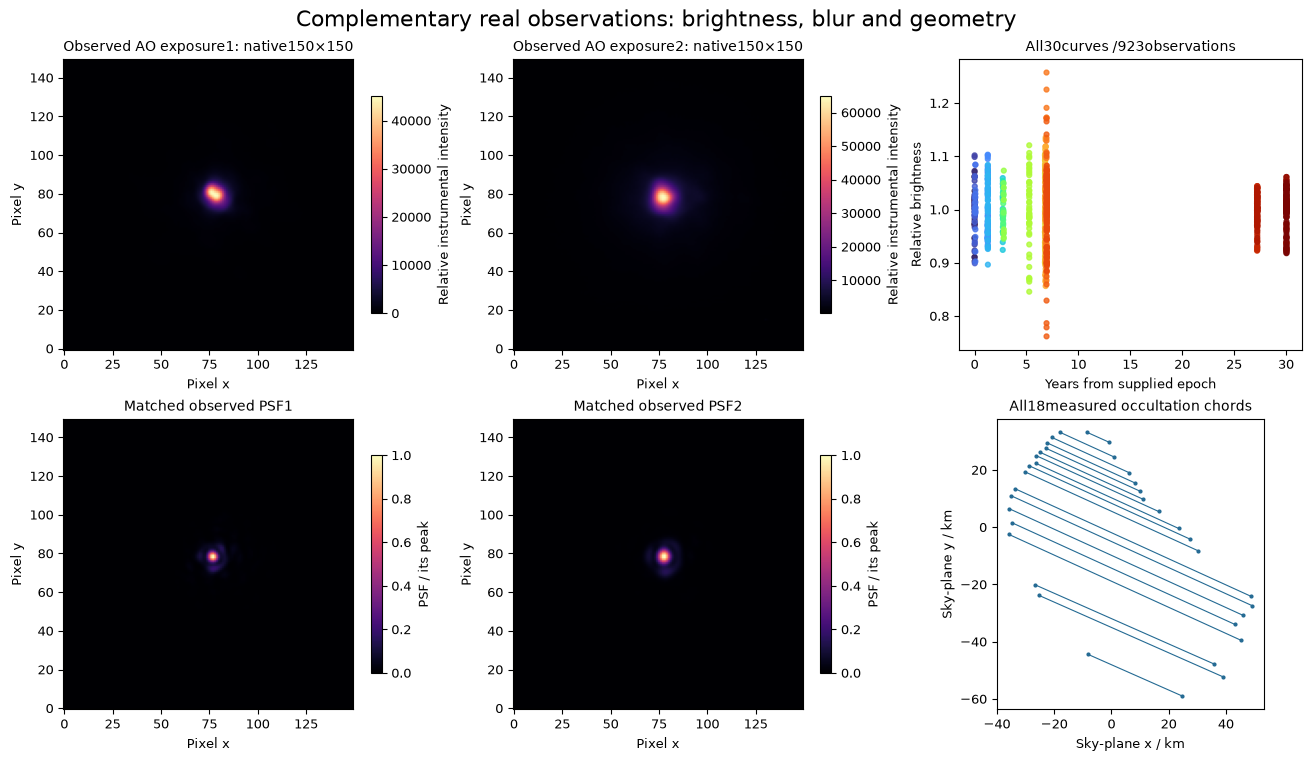

Bound sample counts: 923 11399 complex samples/exposure 18 chords


In [2]:
show(viz.data_figure(raw),'figure1_data',raw)
print('Bound sample counts:',len(data['lc_brightness']),len(data['ao_frequency']),'complex samples/exposure',len(data['oc_chords']),'chords')


## 3. Physics

For facet area $A_t$, outward normal $\boldsymbol n_t$, body-frame observer and
Sun directions, let $\mu_t$ and $\mu_{0t}$ be their normal dot products. Only the
simultaneously illuminated, visible and unblocked set $\mathcal V$ contributes:

$$L=\sum_{t\in\mathcal V}A_t\mu_t\mu_{0t}\left((\mu_t+\mu_{0t})^{-1}+0.1\right).$$

Relative curves divide this model by their own mean. For AO data, each projected
triangle contributes its oriented Fourier integral. With frequency $\boldsymbol f$
in cycles/arcsec, sky position $\boldsymbol u$ in arcsec, known PSF $P$, angular
conversion $d$ in arcsec/km, gain $g$ and Fourier shift $\boldsymbol s$,

$$D(\boldsymbol f)=gP(\boldsymbol f)e^{2\pi\mathrm{i}\boldsymbol f\cdot\boldsymbol s}
\frac{\sum_{t\in\mathcal V}B_t\int_{\Pi(t)}e^{-2\pi\mathrm{i}\boldsymbol f\cdot\boldsymbol u}\,d\boldsymbol u}
{d^2\sum_{t\in\mathcal V}B_t\mu_tA_t},\qquad B_t=\mu_{0t}\left((\mu_t+\mu_{0t})^{-1}+0.1\right).$$

Here $\mathrm{i}$ is the imaginary unit and $\Pi(t)$ the projected triangle.
Occultations instead compare both coordinates of each outer entry/exit
intersection with each measured chord. The independent Judge uses a Green-boundary
triangle integral, rather than importing the reconstruction's analytic kernel.

## 4. Method

Three real harmonic fields $a,b,c$ through degree9 describe coordinate radii in
units1km at fixed colatitude $\theta$ and longitude $\phi$:

$$x=e^a\sin\theta\cos\phi,\quad y=e^{a+b}\sin\theta\sin\phi,\quad z=e^{a+c}\cos\theta.$$

All300harmonic coefficients, three spin quantities, four AO shifts, two log gains
and two occultation shifts are fitted jointly. The full residual $\boldsymbol r$
has46595entries:923photometric,45596real/imaginary AO,72endpoint and4regularizer
entries. The conditional multipliers are8,2,0.1 for these data and30,5,0.5,1 for
convexity,octantoid complexity,dihedral roughness and center-of-mass distance.
They are source modeling choices, not calibrated noise standard deviations.

With $J=-\partial\boldsymbol r/\partial p$, parameter vector $p$, damping
$\lambda$ and normal matrix $N=J^TJ$, the explicit additive update is

$$\left(N+\lambda\operatorname{diag}(N)\right)\Delta p=J^T\boldsymbol r,\qquad
p_{\mathrm{trial}}=p+\Delta p.$$

The native lower-triangle symmetric solve is retained. A decreasing complete
objective accepts the update and divides damping by10; rejection multiplies
damping by10 and reuses the linearization. Two accepted decreases below0.1,
damping above10⁶or100trials stop the loop. The seed is an independent ellipsoid,
not an original reconstruction. The C++17standard-library math is embedded and
auditable; Python owns the complete joint iteration. No domain solver runs here.

The original export writes its `outshape` snapshot before final accepted
coefficients are remeshed. The original comparison below is the captured accepted
state, not that one-step-stale snapshot. The tracked historical executable is
also distinguished from the verified exact Csource. A source-style explicit SH
recurrence caused a complete pole-quality failure, retained as a sensitivity
diagnostic; the validated general Legendre primitive and fixed native grid are
used here. No quality boundary was changed after that failure.

In [3]:
start=time.perf_counter()
fresh,record=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz',progress=lambda row:print(f"trial {row['iteration']:02d}: J={row['objective']:.8f}, trial={row['trial_objective']:.8f}, accepted={row['accepted']}",flush=True))
fresh_runtime=time.perf_counter()-start
report=judge.evaluate(ROOT/'output/reconstruction.npz')
assert report['status']=='pass',report
objective,details=judge.forward_objective(fresh,raw,True)
source_objective,source_details=judge.forward_objective(source,raw,True)
other_objective,other_details=judge.forward_objective(other,raw,True)
history=np.array([[row['iteration'],row['objective'],row['trial_objective'],row['damping'],float(row['accepted'])] for row in record['history']])
initial_mesh,_=octantoid(initial_parameters()[:300]);faces=data['facets']
print(json.dumps(dict(runtime_seconds=fresh_runtime,trials=len(history),fresh_objective=objective,original_O1_objective=source_objective,independent_original_O0_objective=other_objective,judge=report),indent=2))
np.savez_compressed(REFERENCE/'fresh_measurements.npz',parameters=record['parameters'],history=history,lightcurve_model=details['lightcurve_model'],ao_models=details['ao_models'],occultation_endpoints=details['occultation_endpoints'],penalties=details['penalties'])
(REFERENCE/'fresh_metrics.json').write_text(json.dumps(dict(environment=environment,runtime_seconds=fresh_runtime,report=report,components=details['components']),indent=2,allow_nan=False),encoding='utf8')
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')


trial 00: J=399.71622658, trial=721.49054610, accepted=False


trial 01: J=399.71622658, trial=197.13733402, accepted=True


trial 02: J=197.13733402, trial=179.72445654, accepted=True


trial 03: J=179.72445654, trial=1031.60000634, accepted=False


trial 04: J=179.72445654, trial=202.33994518, accepted=False


...

trial 35: J=28.49497444, trial=28.49998360, accepted=False


trial 36: J=28.49497444, trial=28.49571714, accepted=False


trial 37: J=28.49497444, trial=28.49425993, accepted=True


{
  "runtime_seconds": 544.2926393999951,
  "trials": 38,
  "fresh_objective": 28.4942599342202,
  "original_O1_objective": 29.145242464284717,
  "independent_original_O0_objective": 28.492420889211246,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "mesh_x_range_nrmse": 0.0009647612663002938,
      "mesh_y_range_nrmse": 0.0025067309254862406,
      "mesh_z_range_nrmse": 0.004904367260149017,
      "latitude_deg_absolute_error": 0.017151096523093656,
      "longitude_deg_absolute_error": 0.016193896797062735,
      "period_hours_absolute_error": 1.3293060163732662e-07,
      "ao_offsets_rms_arcsec": 5.376813955894787e-05,
      "ao_log_gains_rms_dimensionless": 0.00015410974314812058,
      "occultation_offset_rms_km": 0.0696087630492922,
      "complete_weighted_objective": 28.4942599342202
    },
    "thresholds": {
      "mesh_x_range_nrmse": {
        "comparison": "<=",
        "boundary": 0.0014460159943030682
      },
      "mesh_y_range_nrmse": {


1697

## 5. Results

Every displayed fresh vertex, nuisance quantity and model prediction comes from
the active fit above. The surface is shown in three views with fixed physical
axes. Agreement with the original accepted state and an independent original
O0run is a reproducibility check, not independent truth. Each coordinate uses its
own reference range. The original native subdivision run is preserved as an
author configuration/support comparison; its different weights and578vertex
export mean that it is not a same-weight controlled ablation or a local alternate
solver. Its actual original snapshot is explicitly labeled.

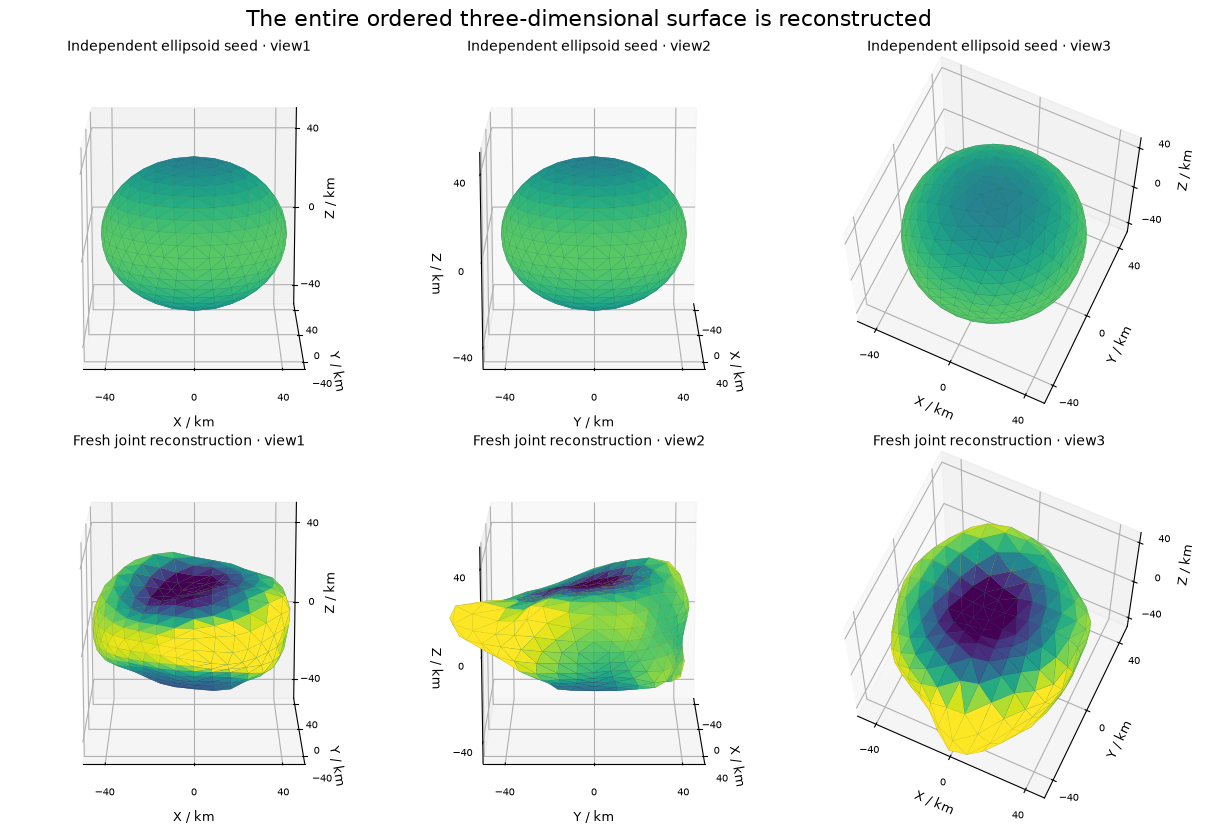

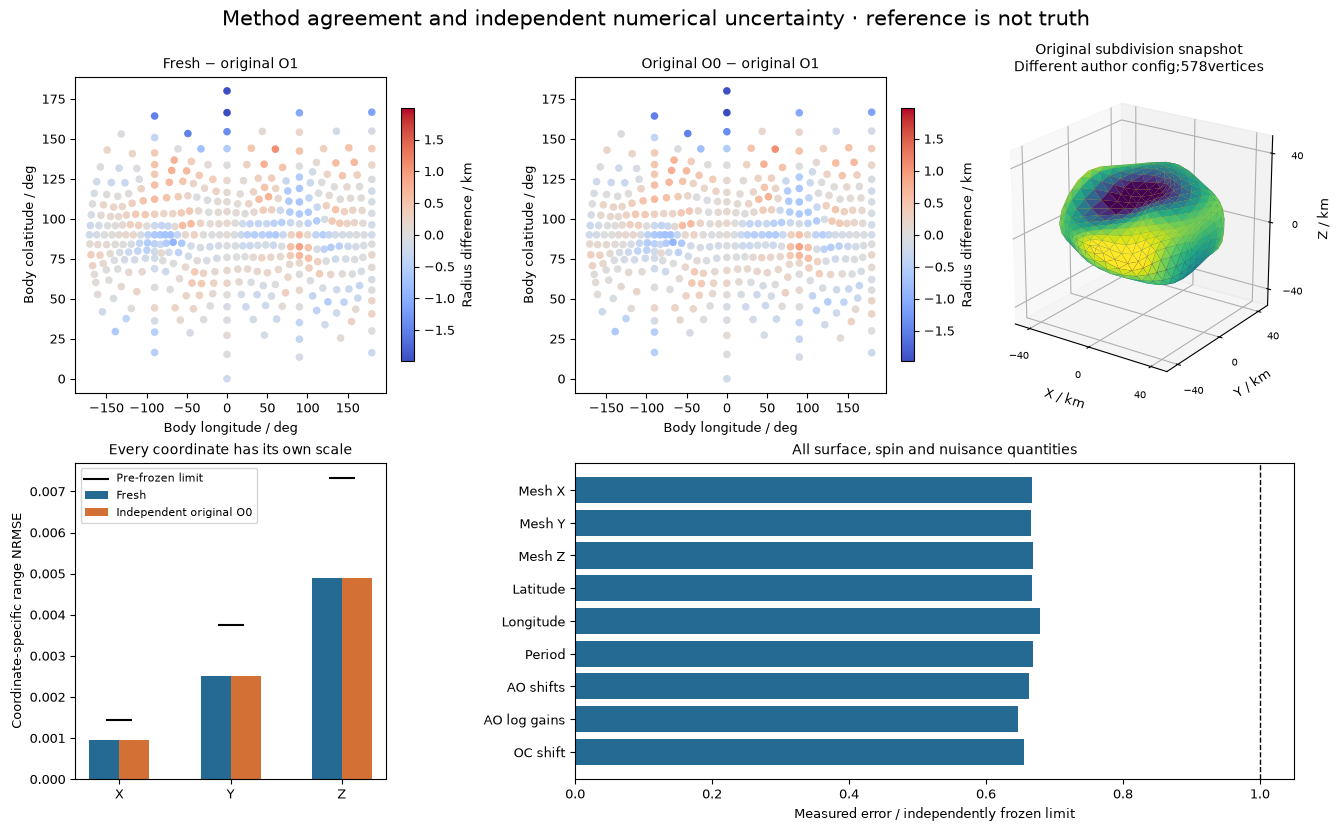

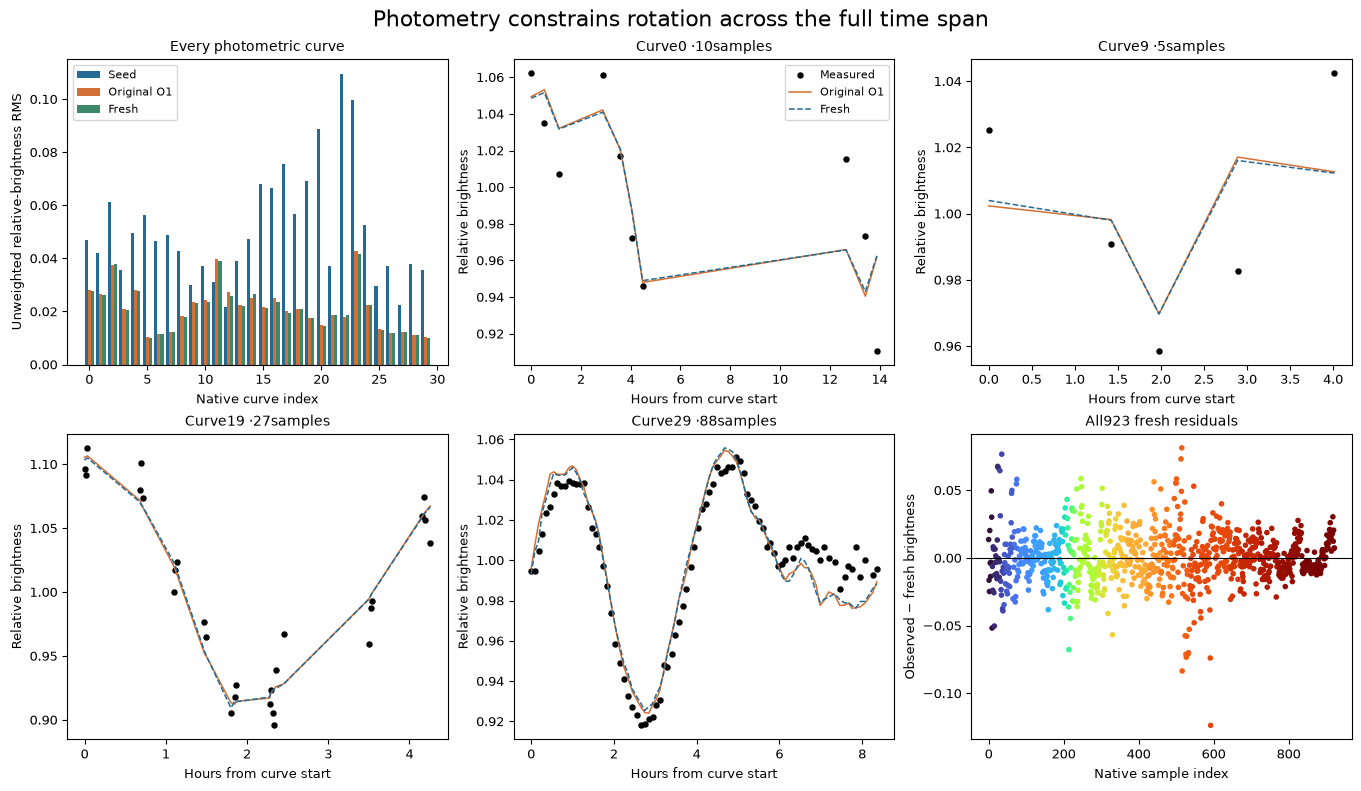

In [4]:
show(viz.shape_figure(initial_mesh,fresh['reconstruction'][0],faces),'figure2_full_surface',dict(initial=initial_mesh,fresh=fresh['reconstruction'],faces=faces))
config=json.loads((ROOT/'evaluation/metrics.json').read_text(encoding='utf8'));boundaries=config['boundaries']
numeric=dict(fresh=fresh['reconstruction'],original=source['reconstruction'],independent_original=other['reconstruction'],subdivision_mesh=subdivision['mesh'],subdivision_faces=subdivision['faces'],metric_values=np.array(list(report['metrics'].values())))
show(viz.comparison_figure(fresh,source,other,subdivision['mesh'],subdivision['faces'],faces,boundaries,report['metrics']),'figure3_reference_uncertainty',numeric)
initial_model=np.empty(923);initial_angles=np.r_[initial_parameters()[300:303],0.]
for curve in range(30):
    rows=np.flatnonzero(data['lc_curve_index']==curve)
    initial_model[rows]=lightcurve_operator(initial_mesh,initial_angles,data['lc_observer'][rows],data['lc_sun'][rows],data['lc_time'][rows],True)[0]
show(viz.lightcurve_figure(data,details,source_details,initial_model),'figure4_all_photometry',dict(time=data['lc_time'],observed=data['lc_brightness'],curve=data['lc_curve_index'],initial=initial_model,original=source_details['lightcurve_model'],fresh=details['lightcurve_model']))


Both image displays use measured image flux as a common scale. The model
image is the inverse-rFFTdisplay of the actually fitted Fourier samples, with
the unmeasured DC term supplied by its normalized model gain; DC was not a fitted
data sample. Signed image residuals use a symmetric zero-centered scale shared
by both exposures. The scientific objective uses all real/imaginary frequency
residuals, not a display crop. The occultation panel shows the projected
triangulation and all chord intersections; no convex outline replaces a
potentially nonconvex silhouette.

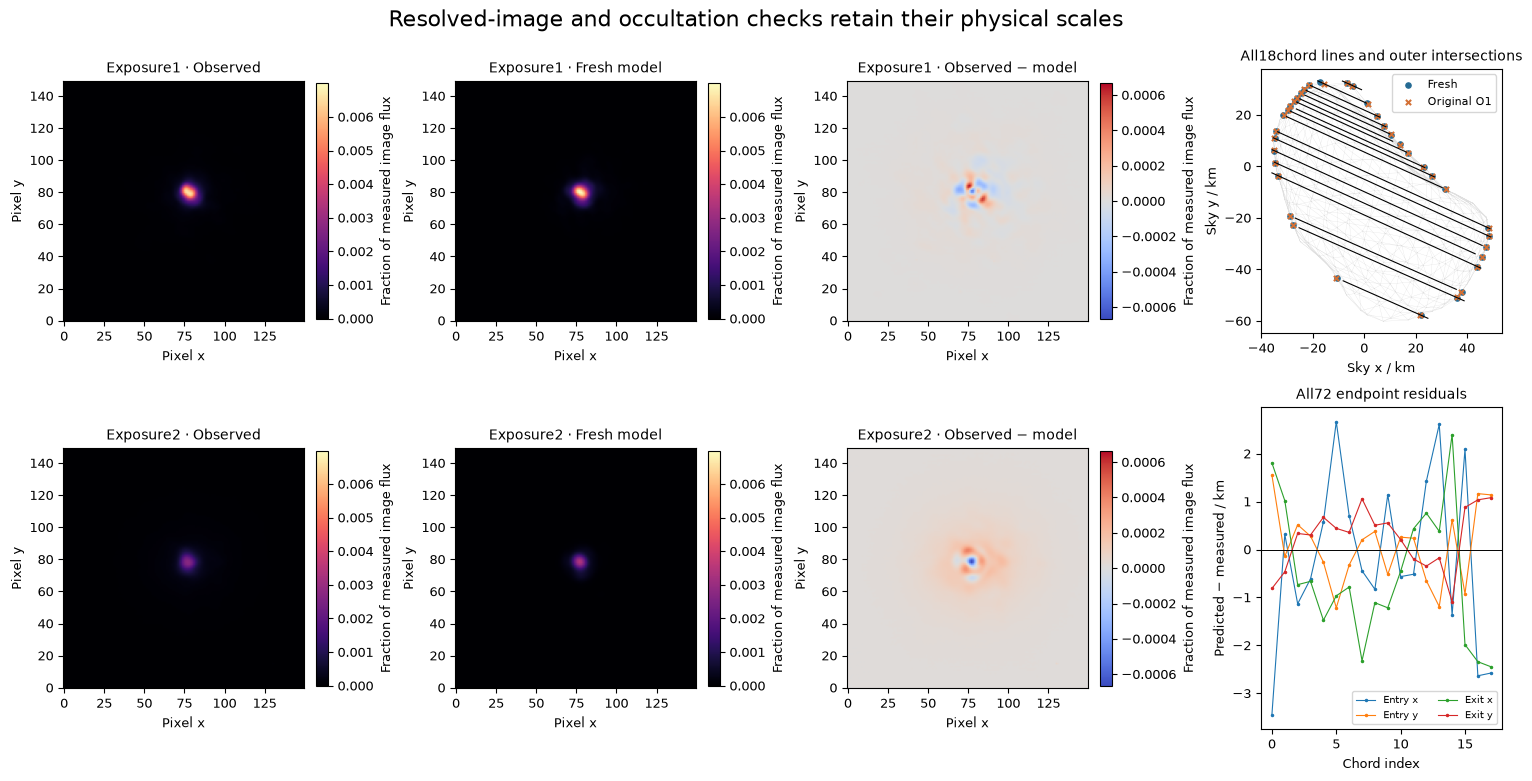

In [5]:
transform=judge._frame(data['oc_observer'][0],data['oc_up'][0])@judge._rotation(fresh['spin'][0],data['oc_time'].mean()).T
projection=(fresh['reconstruction'][0]@transform.T)[:,:2]+fresh['occultation_offset'][0,0]
fig,display_numeric=viz.image_occultation_figure(raw,fresh,details,source_details,projection)
display_numeric.update(fourier_fresh=details['ao_models'],fourier_original=source_details['ao_models'],oc_measured=data['oc_chords'],oc_fresh=details['occultation_endpoints'],oc_original=source_details['occultation_endpoints'],projection=projection)
show(fig,'figure5_images_occultation',display_numeric)


Forward sensitivities below change model parameters while keeping every
observed value fixed. They are actual full-data calculations, not newly generated
observations or a statistical posterior. Uniform shape scale, latitude and period
affect the modalities differently. If a perturbed silhouette misses a detected
chord, the original sigmoid fallback contributes its optimization penalty, not
fabricated physical intersections; the point is annotated with the count. The recorded explicit-recursion failure panel
reports its two actual failed pole metrics divided by the same pre-frozen limits;
it is not presented as another valid solution. Different arithmetic may reach
different nonconvex stopping states despite very accurate initial stages.

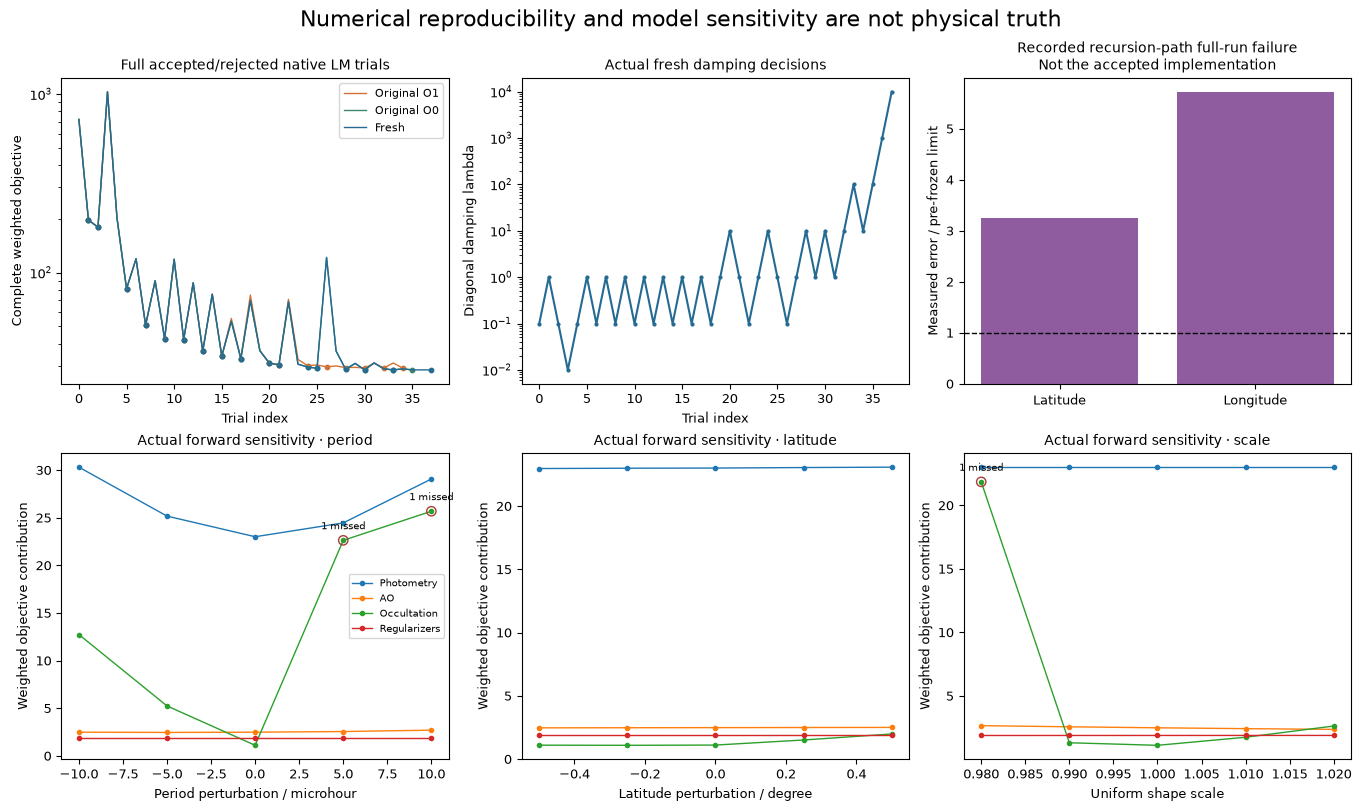

In [6]:
sensitivity={};numeric=dict(fresh_history=history,original_O1_history=source['history'],original_O0_history=other['history'])
for name,x in [('period',np.array([-1e-5,-5e-6,0,5e-6,1e-5])),('latitude',np.array([-.5,-.25,0,.25,.5])),('scale',np.array([.98,.99,1.,1.01,1.02]))]:
    components=[];missed=[]
    for value in x:
        changed={key:array.copy() for key,array in fresh.items()}
        if name=='scale':changed['reconstruction']*=value
        elif name=='period':changed['spin'][0,2]+=value
        else:changed['spin'][0,0]+=value
        _,measured=judge.forward_objective(changed,raw,True)
        components.append(list(measured['components'].values()));missed.append(measured['missed_chord_count'])
    sensitivity[name]=(x,np.array(components),np.array(missed));numeric[name+'_x']=x;numeric[name+'_components']=np.array(components);numeric[name+'_missed_chord_counts']=np.array(missed)
failure=json.loads((REFERENCE/'recurrence_failure_metrics.json').read_text(encoding='utf8'))
ratio=np.array([failure['metrics'][key]/boundaries[key] for key in ['latitude_deg_absolute_error','longitude_deg_absolute_error']]);numeric['recorded_recursion_failure_ratios']=ratio
show(viz.diagnostic_figure(history,source['history'],other['history'],sensitivity,ratio),'figure6_convergence_sensitivity',numeric)


## 6. Conclusion

The active joint fit retains all observations and every output quantity, passes
the independently frozen surface/spin/nuisance gates, and satisfies a separate
full physical forward check. Photometry, blurred resolved images and occultation
endpoints constrain complementary parts of the conditional shape/spin estimate.

The reference is a validated method result, not independent asteroid truth.
Finite angular coverage, constant reflectance, image reduction/blur and finite
harmonic support remain limitations. Independent original O0/O1variation and
the failed recursion-path pole metrics expose numerical/nonconvex uncertainty;
they do not establish physical pole or period precision. The original subdivision
comparison uses its own author configuration. Original data redistribution terms
remain unresolved and are disclosed in NOTICE; local research execution does not
invent a wider license.

The complete numerical path, explicit operator/gradient checks, actual kernel
environment, independent Judge and labeled original/fresh comparisons make this
a reviewable computational inverse, with no original domain runtime dependency.